# Istanbul earthquake scenario: neighbourhood-level analysis

This notebook works with the earthquake scenario results published by the Istanbul
Metropolitan Municipality (IMM / İBB) for 959 neighbourhoods (mahalle) in 39 districts.

The numbers in the table are **outputs of the municipality's scenario model** (estimated
building damage, casualties and needs for one hypothetical earthquake). They are not
observed events. The models below therefore measure how well the published casualty
estimates can be reproduced from the published damage estimates; they do not predict
what would happen in a real earthquake.

Steps:
1. Load and clean the table.
2. Join neighbourhoods to boundary polygons from OpenStreetMap.
3. Build a weighted building-damage index, test its sensitivity to the weights, rank
   neighbourhoods and districts.
4. Cross-validate models of deaths + serious injuries from the four damage counts.
5. Add residents (TÜİK ADNKS 2019) and building stock (IMM 2017) to compute per-capita and
   per-building rates, and test residents as model exposure.
6. Describe the pipeline damage and temporary shelter columns.
7. Save static figures (`figures/`), tables (`results/`) and an interactive map (`maps/`).

The same steps run without Jupyter via `python scripts/build_outputs.py`.

In [1]:
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from eqscenario import data, geo, index, infrastructure, modeling, plots
from eqscenario import population as popn

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
FIG, RES = ROOT / "figures", ROOT / "results"
FIG.mkdir(exist_ok=True)
RES.mkdir(exist_ok=True)

## 1. Data

The CSV is Windows-1254 (Turkish) encoded. Reading it as `cp1254` gives correct Turkish
letters directly. `EYÜP` is renamed to `EYÜPSULTAN` (renamed in 2017) so it matches the
boundary data.

In [2]:
df = data.load_scenario()
print(df.shape, "rows x columns;", df["district"].nunique(), "districts")
df[["district", "neighbourhood"] + data.DAMAGE_COLS + ["can_kaybi_sayisi", "agir_yarali_sayisi"]].head()

(959, 19) rows x columns; 39 districts


,district,neighbourhood,cok_agir_hasarli_bina_sayisi,agir_hasarli_bina_sayisi,orta_hasarli_bina_sayisi,hafif_hasarli_bina_sayisi,can_kaybi_sayisi,agir_yarali_sayisi
0,Adalar,Burgazada,54,99,256,241,8,6
1,Adalar,Heybeliada,101,175,423,393,25,21
2,Adalar,Kınalıada,53,97,287,302,5,3
3,Adalar,Maden,104,192,483,484,22,18
4,Adalar,Nizam,101,180,445,422,16,13


In [3]:
totals = df[data.DAMAGE_COLS + data.CASUALTY_COLS + ["gecici_barinma"]].sum()
totals.rename("Istanbul total").to_frame()

,Istanbul total
cok_agir_hasarli_bina_sayisi,13496
agir_hasarli_bina_sayisi,34334
orta_hasarli_bina_sayisi,146512
hafif_hasarli_bina_sayisi,301524
can_kaybi_sayisi,14145
agir_yarali_sayisi,8090
hastanede_tedavi_sayisi,39636
hafif_yarali_sayisi,75240
gecici_barinma,835918


## 2. Neighbourhood polygons

The polygons come from OpenStreetMap (compiled through the Nominatim API in the
`sahircansurmeli/istanbul-geojson` repository, pinned to a commit). They are downloaded on
first run into `data/external/` and are not committed. Licence: ODbL 1.0,
(c) OpenStreetMap contributors.

Each polygon is assigned to the district whose polygon contains its representative point,
then matched on normalised (district, neighbourhood) names, with a short alias list for
spelling differences and renames.

In [4]:
districts = geo.load_districts()
polys = geo.load_neighbourhood_polygons()
nb = geo.attach_polygons(index.add_index(df), polys)
print("usable district-assigned polygons:", len(polys))
print("scenario rows with a polygon:", nb.geometry.notna().sum(), "of", len(nb))
nb.loc[nb.geometry.isna(), ["district", "neighbourhood"]]

usable district-assigned polygons: 967
scenario rows with a polygon: 953 of 959


,district,neighbourhood
95,Bahçelievler,Fevzi Çakmak
96,Bahçelievler,Hürriyet
97,Bahçelievler,Kocasinan Merkez
228,Beyoğlu,Evliya Çelebi
236,Beyoğlu,İstiklal
726,Silivri,Gümüşyaka


## 3. Weighted building-damage index

The table gives four damage levels: very heavy (çok ağır), heavy (ağır), moderate (orta)
and light (hafif). The index prioritises severe damage using analyst-chosen weights.
They are not official IMM weights or calibrated replacement-cost ratios:

| level | weight |
| --- | --- |
| very heavy | 1.00 |
| heavy | 0.50 |
| moderate | 0.10 |
| light | 0.02 |

`damage_index = 1.0*very_heavy + 0.5*heavy + 0.1*moderate + 0.02*light`, i.e. the number of
very-heavy-damage-equivalent buildings, a ranking proxy rather than a literal loss estimate.
`severity` = index / damaged buildings is the average severity weight among damaged buildings.

The index measures physical damage. The table has no building stock or population, so it
is not normalised by exposure.

In [5]:
sens = index.sensitivity(nb)
sens.round(3).to_csv(RES / "weight_sensitivity.csv", index=False)
sens.round(3)

,scheme,"weights (vh, h, m, l)",spearman_vs_main,top50_overlap_with_main,spearman_vs_deaths_serious
0,severity weights (main),"1, 0.5, 0.1, 0.02",1.000,1.00,0.839
1,linear 4-3-2-1,"4, 3, 2, 1",0.981,0.78,0.802
2,equal (count),"1, 1, 1, 1",0.958,0.74,0.779
3,steep 1-0.25-0.05-0.01,"1, 0.25, 0.05, 0.01",0.998,0.96,0.850
4,collapse only,"1, 0, 0, 0",0.959,0.78,0.874


The overall ranking is stable across weighting schemes (Spearman rank correlation with the
main scheme between 0.958 and 0.998). The top-50 list is more sensitive: 74 to 96 percent of
it is shared with the main scheme. The "collapse only" scheme tracks casualties most closely,
which is expected because the scenario casualties depend mostly on very heavy damage (see
section 4).

In [6]:
cols = ["rank", "district", "neighbourhood", "damage_index", "severity", "damaged_buildings",
        "cok_agir_hasarli_bina_sayisi", "deaths_serious"]
nb_table = nb.sort_values("rank")[cols + ["mahalle_koy_uavt", "can_kaybi_sayisi",
                                          "gecici_barinma"]].assign(has_polygon=nb.geometry.notna())
nb_table.round(3).to_csv(RES / "neighbourhood_index.csv", index=False)
nb_table[cols].head(15).round(2)

,rank,district,neighbourhood,damage_index,severity,damaged_buildings,cok_agir_hasarli_bina_sayisi,deaths_serious
114,1,Bakırköy,Yeşilköy,438.02,0.24,1828,201,253
69,2,Avcılar,Yeşilkent,398.04,0.09,4366,36,63
588,3,Küçükçekmece,Kanarya,337.90,0.14,2363,116,235
586,4,Küçükçekmece,İnönü,336.88,0.13,2661,95,226
102,5,Bahçelievler,Zafer,314.02,0.12,2596,101,326
875,6,Tuzla,Şifa,303.96,0.17,1747,103,131
112,7,Bakırköy,Şenlikköy,296.06,0.21,1425,110,190
133,7,Bayrampaşa,Muratpaşa,296.06,0.15,1915,116,156
581,9,Küçükçekmece,Cumhuriyet,292.16,0.17,1747,109,237
438,10,Fatih,Ayvansaray,291.76,0.17,1741,111,103


In [7]:
dist = index.district_index(nb)
dist.round(3).to_csv(RES / "district_index.csv", index=False)
dist.head(10).round(2)

,district,damage_index,damaged_buildings,deaths_serious,can_kaybi_sayisi,gecici_barinma,severity,rank
0,Fatih,5141.06,31286,2469,1484,46784,0.16,1
1,Küçükçekmece,3721.78,26633,2440,1515,72774,0.14,2
2,Bağcılar,2816.54,26019,1831,1179,59513,0.11,3
3,Esenyurt,2531.54,24914,1546,1003,67410,0.10,4
4,Bahçelievler,2301.52,17640,2512,1633,61199,0.13,5
5,Silivri,2252.94,21303,85,58,13481,0.11,6
6,Büyükçekmece,2106.04,18063,442,288,24298,0.12,7
7,Bakırköy,1853.18,9421,1627,1046,28910,0.20,8
8,Tuzla,1826.78,15365,437,268,21417,0.12,9
9,Bayrampaşa,1759.20,13270,860,520,23064,0.13,10


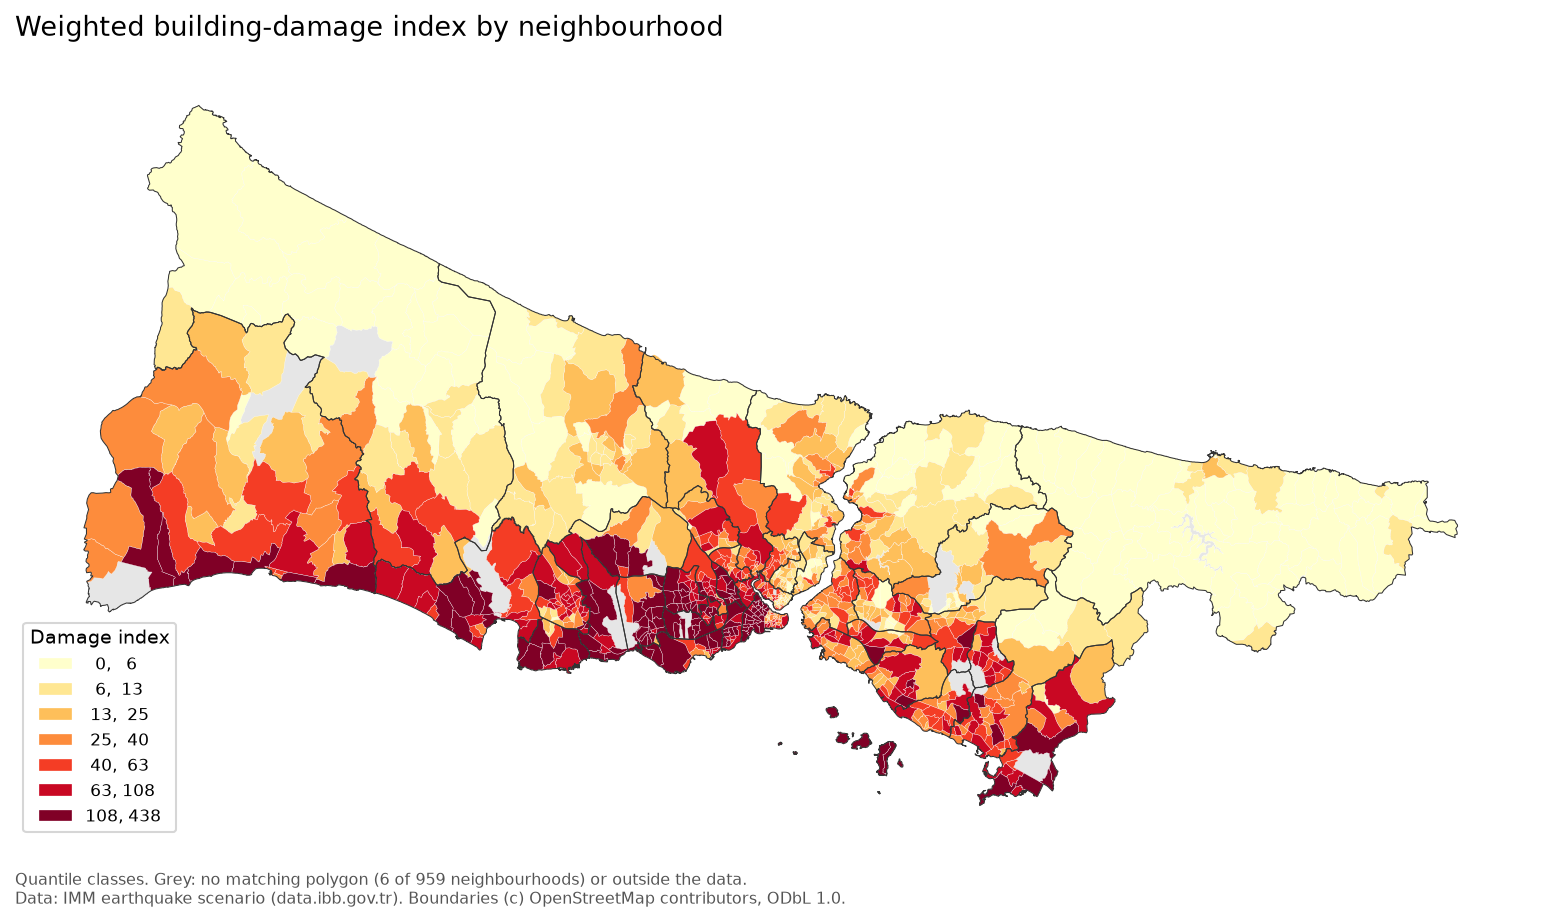

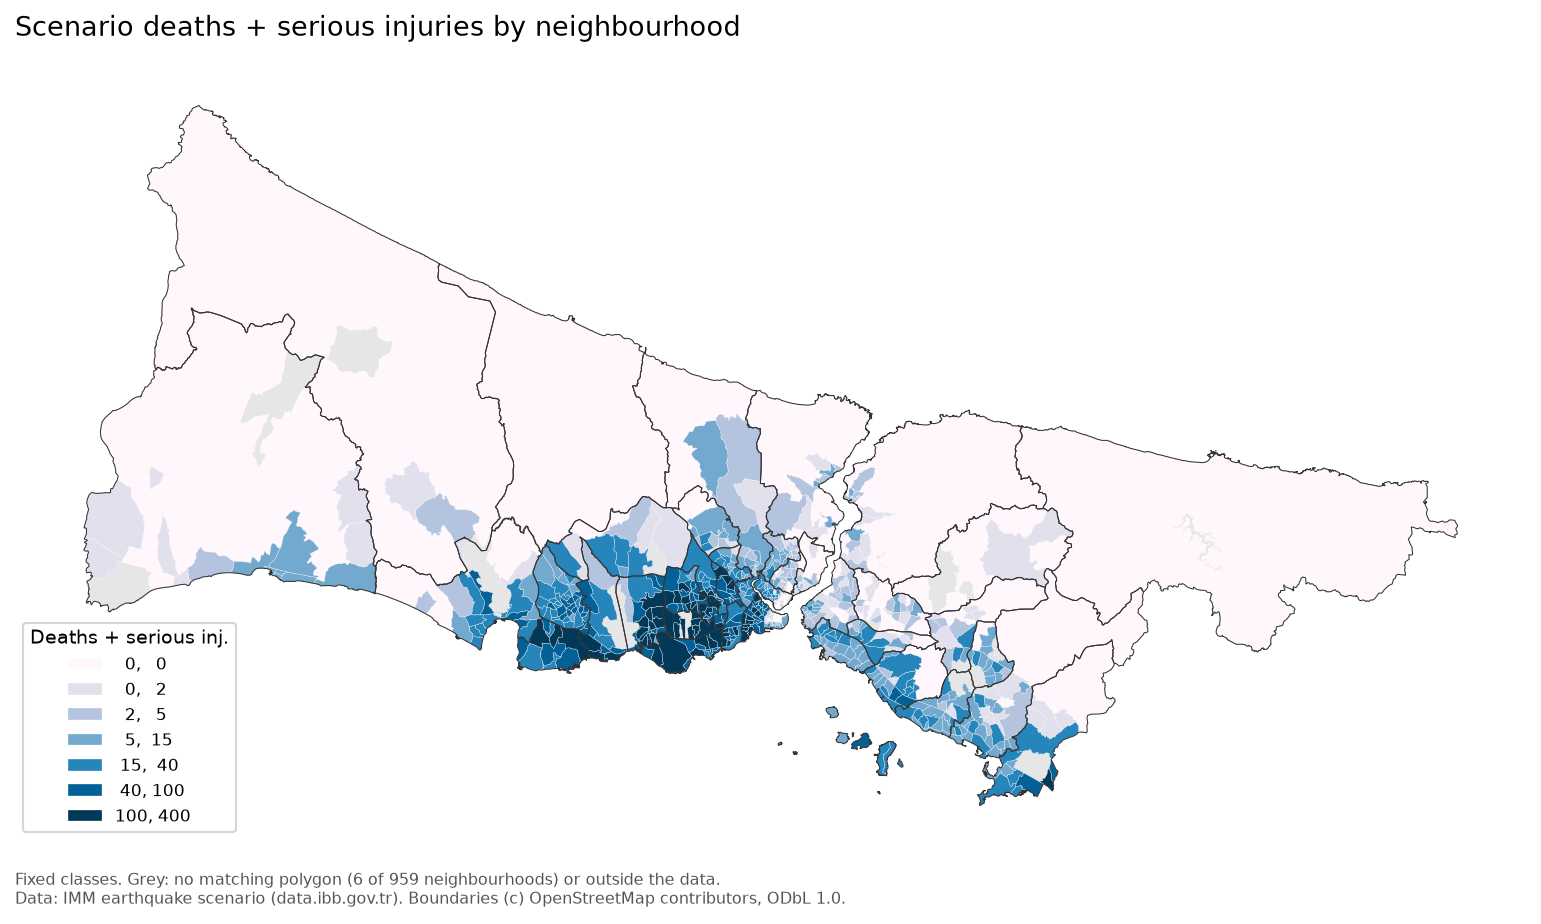

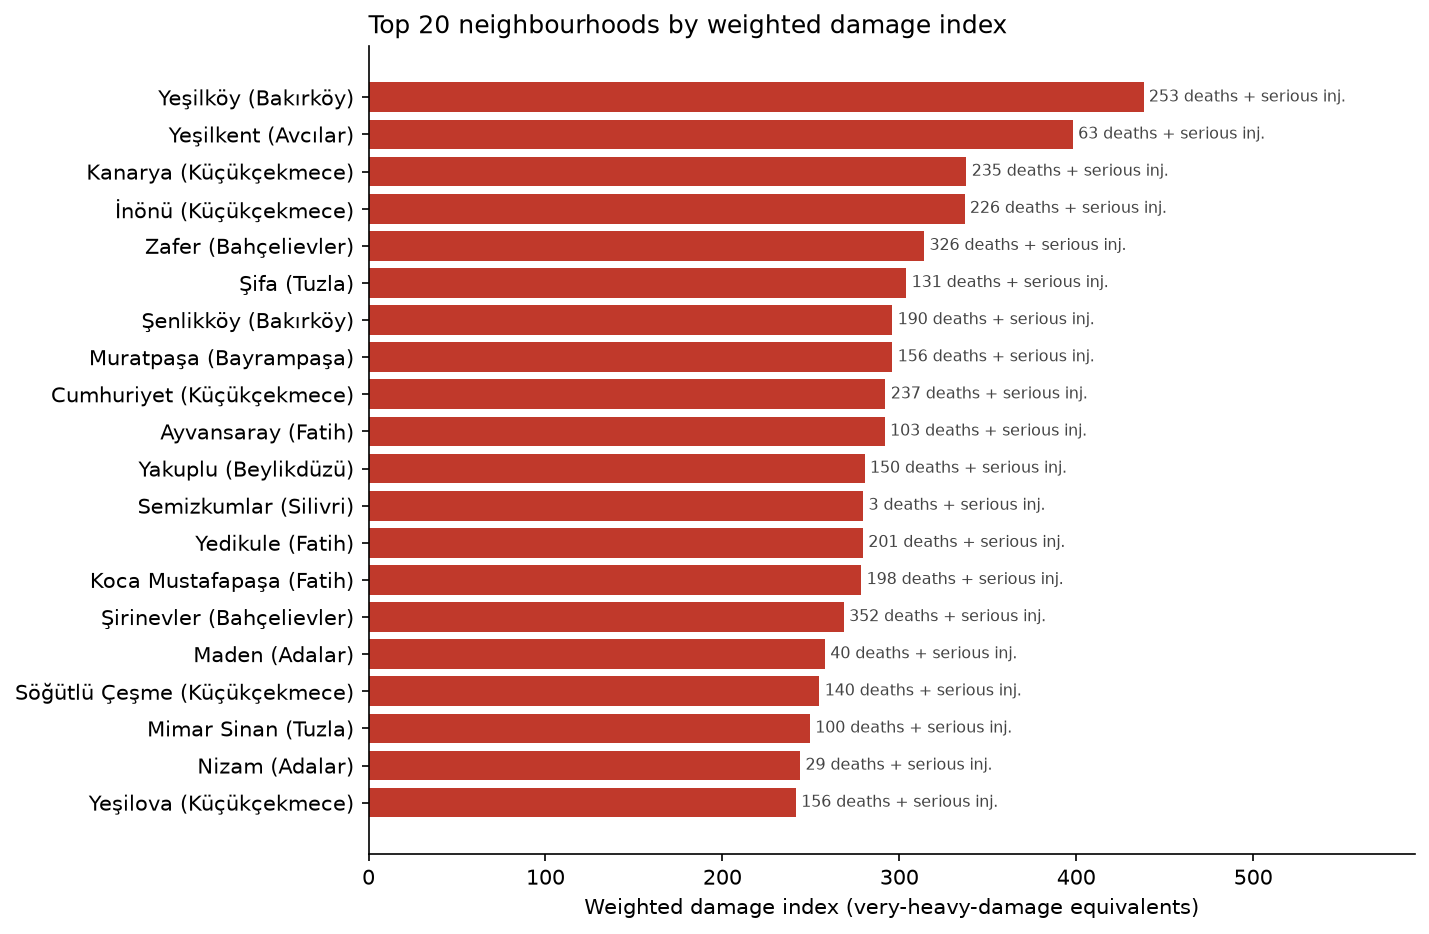

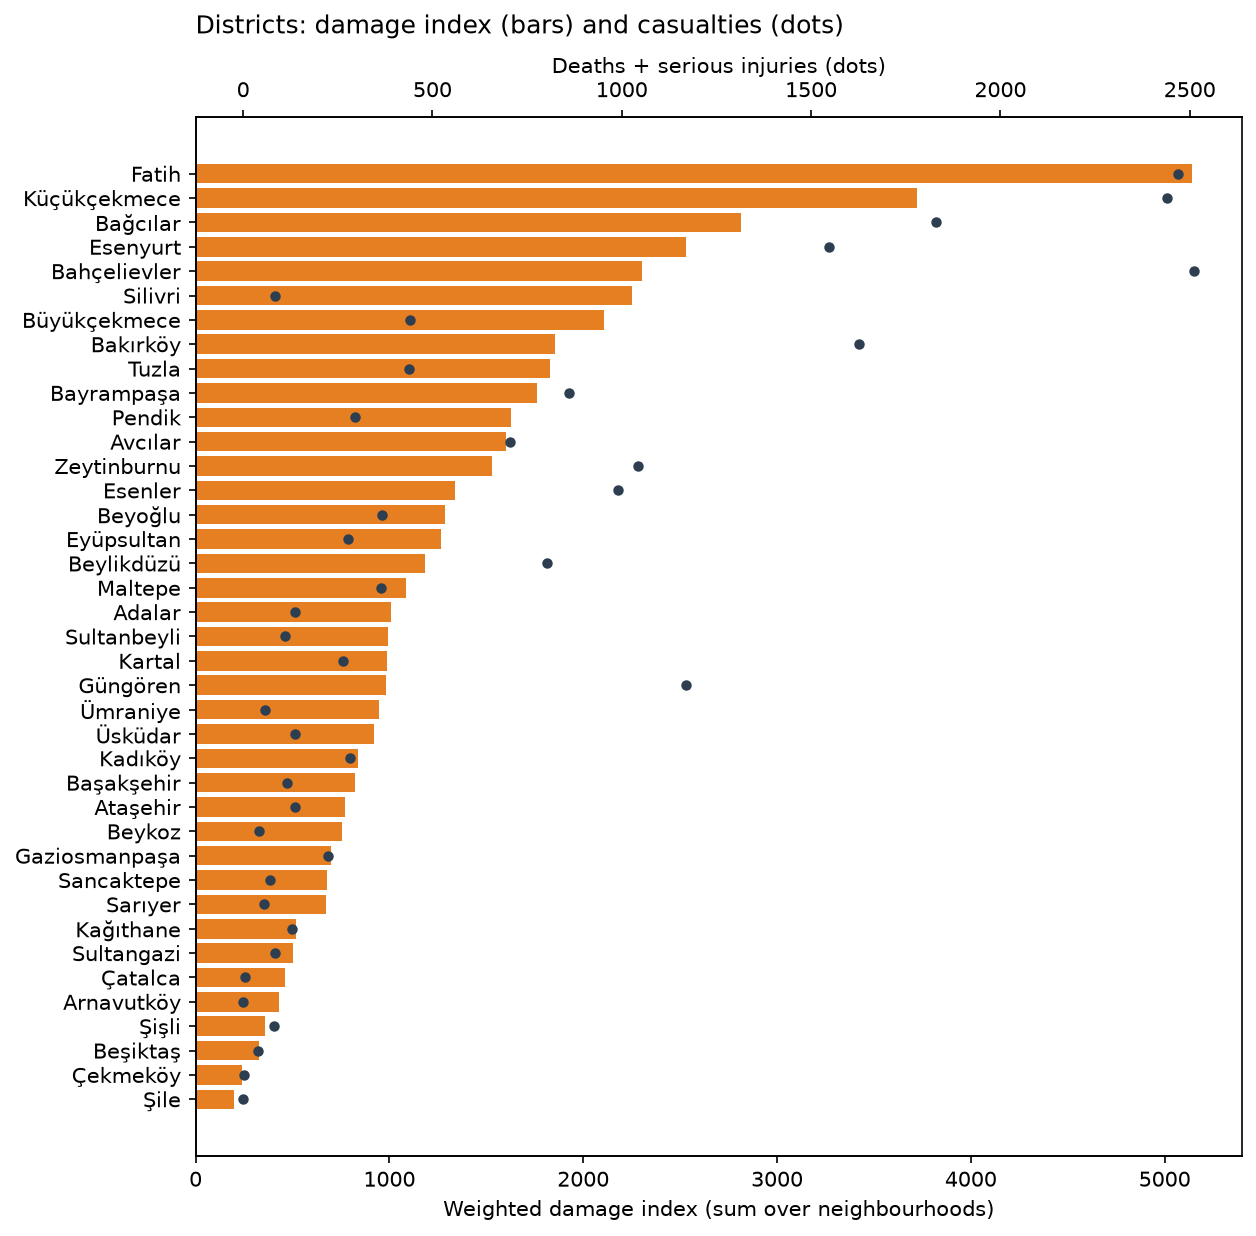

In [8]:
plots.choropleth(nb, districts, "damage_index", "Weighted building-damage index by neighbourhood",
                 "Damage index", FIG / "damage_index_map.png")
plots.choropleth(nb, districts, "deaths_serious", "Scenario deaths + serious injuries by neighbourhood",
                 "Deaths + serious inj.", FIG / "casualties_map.png", cmap="PuBu",
                 bins=[0, 2, 5, 15, 40, 100, 400])
plots.top_neighbourhoods_bar(nb, FIG / "top_neighbourhoods.png")
plots.district_bar(districts.merge(dist, on="district", how="left"), FIG / "district_index.png")
for name in ["damage_index_map", "casualties_map", "top_neighbourhoods", "district_index"]:
    display(Image(filename=str(FIG / f"{name}.png"), width=850))

## 4. Models: deaths + serious injuries from damage counts

Target: `can_kaybi_sayisi + agir_yarali_sayisi` per neighbourhood. Features: the four damage
counts. Models:

- ratio baseline: casualties proportional to very heavily damaged buildings (no intercept);
- linear regression on the four counts;
- Poisson GLM (log link) on `log1p` of the counts, which fits count data and allows a
  power-law relation;
- histogram gradient boosting with Poisson loss.

Two 5-fold schemes: random folds, and folds grouped by district (all neighbourhoods of a
district are in the same fold). The grouped scheme tests transfer to districts the model has
not seen; neighbourhoods of one district share building stock and distance to the fault, so
random folds are optimistic. Poisson deviance is computed with predictions floored at 0.001
(linear regression can predict negative values).

In [9]:
folds, summary, oof = modeling.cross_validate(nb)
folds.round(4).to_csv(RES / "cv_folds.csv", index=False)
summary.round(3).to_csv(RES / "cv_summary.csv", index=False)
summary.round(3)

,split,model,r2_mean,r2_std,mae_mean,mae_std,poisson_dev_mean,poisson_dev_std
0,random 5-fold,Ratio baseline (very heavy only),0.711,0.040,11.698,2.174,10.921,2.037
1,random 5-fold,Linear regression,0.747,0.035,12.157,1.530,17.290,5.066
2,random 5-fold,Poisson GLM (log1p features),0.763,0.060,10.219,1.705,9.416,1.597
3,random 5-fold,Gradient boosting (Poisson loss),0.691,0.040,11.230,2.134,10.869,2.436
4,grouped by district 5-fold,Ratio baseline (very heavy only),0.587,0.397,11.666,3.424,11.087,4.466
5,grouped by district 5-fold,Linear regression,0.646,0.295,12.398,2.961,21.737,16.081
6,grouped by district 5-fold,Poisson GLM (log1p features),0.652,0.253,10.682,3.530,10.055,3.884
7,grouped by district 5-fold,Gradient boosting (Poisson loss),0.553,0.319,12.227,4.875,12.819,5.338


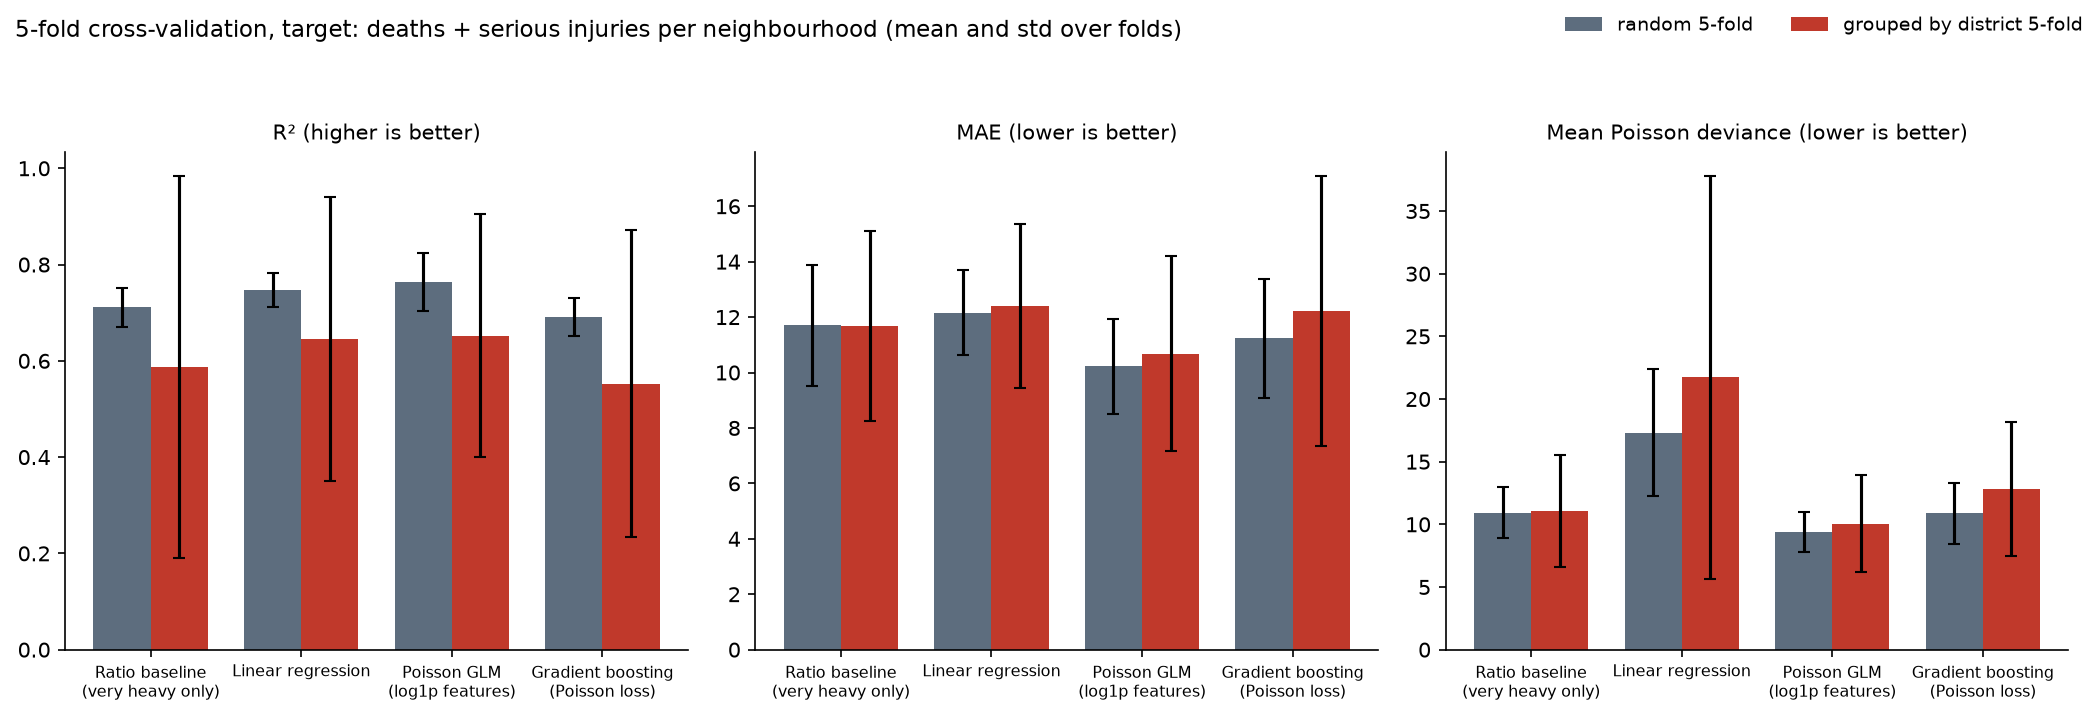

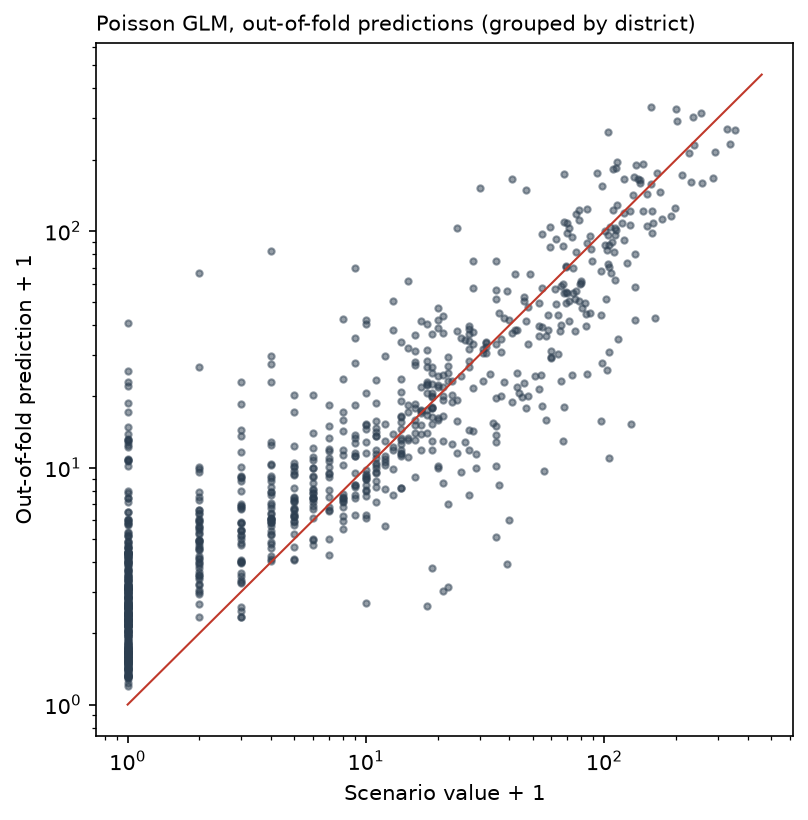

In [10]:
plots.model_comparison(summary, FIG / "model_comparison.png")
best = ("grouped by district 5-fold", "Poisson GLM (log1p features)")
plots.oof_scatter(nb[modeling.TARGET].to_numpy(), oof[best],
                  "Poisson GLM, out-of-fold predictions (grouped by district)",
                  FIG / "oof_poisson_glm.png")
display(Image(filename=str(FIG / "model_comparison.png"), width=950))
display(Image(filename=str(FIG / "oof_poisson_glm.png"), width=450))

### Which damage level drives casualties?

1. Casualties per building at each level from a non-negative linear fit without intercept.
2. Grouped-CV R² of a Poisson GLM that sees only one damage level.

In [11]:
rates = modeling.per_building_rates(nb)
rates.round(4).to_csv(RES / "per_building_rates.csv", index=False)
rates.round(4)

,damage_level,buildings_total,casualties_per_building,share_of_fitted_casualties
0,very heavy,13496,1.6700,0.9328
1,heavy,34334,0.0000,0.0000
2,moderate,146512,0.0000,0.0000
3,light,301524,0.0054,0.0672


In [12]:
single = modeling.single_feature_cv(nb)
single.round(3).to_csv(RES / "single_feature_cv.csv", index=False)
single.round(3)

,damage_level,grouped_cv_r2_mean,grouped_cv_r2_std,pooled_oof_r2,spearman_with_target
0,very heavy,0.499,0.494,0.655,0.874
1,heavy,0.339,0.626,0.505,0.831
2,moderate,0.187,0.513,0.323,0.787
3,light,0.138,0.266,0.256,0.726


In [13]:
vh = nb["cok_agir_hasarli_bina_sayisi"].sum()
print(f"deaths per very heavily damaged building: {nb['can_kaybi_sayisi'].sum() / vh:.2f}")
print(f"deaths + serious injuries per very heavily damaged building: {nb['deaths_serious'].sum() / vh:.2f}")
print("correlation between damage levels (Spearman):")
nb[data.DAMAGE_COLS].corr(method="spearman").round(2)

deaths per very heavily damaged building: 1.05
deaths + serious injuries per very heavily damaged building: 1.65
correlation between damage levels (Spearman):


,cok_agir_hasarli_bina_sayisi,agir_hasarli_bina_sayisi,orta_hasarli_bina_sayisi,hafif_hasarli_bina_sayisi
cok_agir_hasarli_bina_sayisi,1.00,0.97,0.90,0.77
agir_hasarli_bina_sayisi,0.97,1.00,0.97,0.86
orta_hasarli_bina_sayisi,0.90,0.97,1.00,0.95
hafif_hasarli_bina_sayisi,0.77,0.86,0.95,1.00


The Poisson GLM has the lowest MAE and deviance in both split schemes. Its mean R² falls
from 0.763 with random folds to 0.652 with district-held-out folds; the grouped-fold standard
deviation is 0.253, so performance differs substantially across district groups. These are
fixed model comparisons, not nested hyperparameter tuning or an external validation set.

Very heavy damage is the strongest individual feature, but its mean grouped-fold R² of
0.499 is below the four-feature GLM's 0.652. The single-feature table also reports pooled
out-of-fold R², which must not be compared with mean fold R². In the descriptive non-negative
fit, very heavy damage accounts for 93 percent of fitted deaths + serious injuries. The
features are correlated, so zero coefficients for heavy and moderate damage do not establish
that those damage levels cause no casualties.

## 5. Per-capita risk

The scenario table has counts only, so a large neighbourhood ranks high simply because many
people live there. Two official tables, both keyed by the national address database (UAVT)
neighbourhood code that the scenario table also carries, fill the gap:

- **Residents:** TÜİK address-based population registration (ADNKS), "Belediye, köy ve mahalle
  nüfusları", exported from the TÜİK MEDAS database for 2018 to 2020
  (`data/tuik_adnks_mahalle_population_2018_2020.csv`). The analysis uses 31 December 2019:
  the loss estimation project behind the scenario is dated 2019, it is a night-time scenario
  that places the registered population at home, and the IMM district booklets quote the TÜİK
  2019 figures. TÜİK allows reuse of data from its databases with attribution.
- **Buildings:** IMM Open Data "Mahalle Bazlı Bina Sayıları", 2017 building counts by
  construction period and floor class (1 to 19 floors), IMM Open Data Licence
  (`data/ibb_mahalle_building_counts_2017.csv`).

In [14]:
pop = popn.load_population()
print(pop.groupby("year")["population"].agg(["size", "sum"]))
nb, tuik_without_scenario = popn.attach_population(nb, pop)
print(nb["population_match"].value_counts())
popn.join_report(nb, tuik_without_scenario)

      size       sum
year                
2018   964  15067713
2019   964  15519262
2020   963  15462433
population_match
uavt                 951
uavt code changed      8
Name: count, dtype: int64


,district,neighbourhood,mahalle_koy_uavt,tuik_uavt,population,note
0,Beykoz,Poyrazköy,16634,191719,905,scenario carries the former village code
1,Silivri,Büyük Kılıçlı,16775,191849,1160,scenario carries the former village code
2,Silivri,Büyük Sinekli,16771,191843,407,scenario carries the former village code
3,Silivri,Fener,16765,191839,1472,scenario carries the former village code
4,Silivri,Küçük Sinekli,16779,191857,166,scenario carries the former village code
5,Şile,Bozgoca,16785,191865,102,scenario carries the former village code
6,Şile,Gökmaşlı,16807,191907,199,scenario carries the former village code
7,Şile,Teke,16816,191925,495,scenario carries the former village code
8,Başakşehir,İkitelli Osb,<NA>,139666,83,TÜİK neighbourhood without a scenario row
9,Beylikdüzü,Beylikdüzüosb,<NA>,40896,14,TÜİK neighbourhood without a scenario row


All 959 scenario rows get a population. 951 join directly on the UAVT code. Eight former
villages in Beykoz, Silivri and Şile carry their old village code (16xxx) in the scenario table
and a newer neighbourhood code (191xxx) at TÜİK; they are mapped explicitly in
`population.UAVT_CHANGES`, and a test checks that district and name agree for each pair. Five
TÜİK neighbourhoods have no scenario row: three organised industrial zones (113 residents in
total) and Finanskent and Yenişehir in Ümraniye (7,174 residents), which are in the 2018 to 2020
TÜİK data but not in the scenario's neighbourhood list. Their residents (0.05 percent of the
city) are left out; the scenario does not say which of its neighbourhoods covers them.

In [15]:
nb = popn.attach_buildings(nb, popn.load_buildings())
nb = popn.add_rates(nb)
print("buildings in the 2017 inventory:", int(nb["buildings"].sum()))
print("damaged share of stock:", round(nb["damaged_buildings"].sum() / nb["buildings"].sum(), 3))
thr = popn.per_capita_threshold_table(nb)
thr.round(3).to_csv(RES / "per_capita_threshold_sensitivity.csv", index=False)
thr.round(3)

buildings in the 2017 inventory: 1165936
damaged share of stock: 0.425


,min_population,neighbourhoods,residents_covered_share,max_casualties_per_1000,top20_median_population,top20_overlap_with_main,spearman_casualties_vs_per_capita
0,0,959,1.000,26.786,1951.5,0.60,0.937
1,250,910,0.999,13.793,3861.5,0.75,0.934
2,500,863,0.998,13.793,4291.5,0.85,0.931
3,1000,811,0.996,13.793,5750.0,1.00,0.931
4,2000,747,0.990,13.793,7559.5,0.90,0.935
5,5000,654,0.970,13.793,13210.0,0.60,0.951


**Minimum population.** Per-capita rankings only include neighbourhoods with at least
1,000 residents (`population.MIN_POPULATION`). The city-wide rate is about 1.4 deaths +
serious injuries per 1,000 residents, so below 1,000 residents a single scenario casualty moves
the rate by at least 1 per 1,000, about the size of the city average. Without a threshold the
top of the list is the historic commercial core of Fatih and Beyoğlu (for example 3 casualties
among 112 residents in Kemankeş Karamustafapaşa, 26.8 per 1,000). The 148 excluded
neighbourhoods hold 0.4 percent of residents and 44 of 22,235 scenario casualties. Between 500
and 2,000 residents the top-20 list shares 85 to 100 percent of its members with the main list.

In [16]:
cols = ["district", "neighbourhood", "population", "deaths_serious", "casualties_per_1000",
        "deaths_per_1000", "rank_casualties_per_1000"]
abs_rank = nb["deaths_serious"].rank(ascending=False, method="min").astype(int)
print("Top 10 per capita (at least 1,000 residents)")
display(nb[nb["eligible"]].nlargest(10, "casualties_per_1000")[cols].assign(absolute_rank=abs_rank).round(2))
print("Top 10 by absolute deaths + serious injuries")
display(nb.nlargest(10, "deaths_serious")[cols].assign(absolute_rank=abs_rank).round(2))

Top 10 per capita (at least 1,000 residents)


,district,neighbourhood,population,deaths_serious,casualties_per_1000,deaths_per_1000,rank_casualties_per_1000,absolute_rank
107,Bakırköy,Basınköy,5945,82,13.79,7.91,1,88
1,Adalar,Heybeliada,4253,46,10.82,5.88,2,155
488,Fatih,Yedikule,18879,201,10.65,6.25,3,13
103,Bakırköy,Ataköy 1. Kısım,1691,18,10.64,7.10,4,260
114,Bakırköy,Yeşilköy,24669,253,10.26,6.53,5,7
0,Adalar,Burgazada,1427,14,9.81,5.61,6,306
949,Zeytinburnu,Kazlıçeşme,2212,21,9.49,5.88,7,234
113,Bakırköy,Yenimahalle,6865,65,9.47,6.12,8,122
3,Adalar,Maden,4330,40,9.24,5.08,9,168
460,Fatih,Koca Mustafapaşa,21520,198,9.20,5.58,10,14


Top 10 by absolute deaths + serious injuries


,district,neighbourhood,population,deaths_serious,casualties_per_1000,deaths_per_1000,rank_casualties_per_1000,absolute_rank
100,Bahçelievler,Şirinevler,64189,352,5.48,3.58,43,1
98,Bahçelievler,Siyavuşpaşa,65518,337,5.14,3.36,55,2
102,Bahçelievler,Zafer,85981,326,3.79,2.47,96,3
99,Bahçelievler,Soğanlı,70571,290,4.11,2.68,81,4
92,Bahçelievler,Bahçelievler,61726,284,4.60,3.00,64,5
109,Bakırköy,Kartaltepe,38117,255,6.69,4.36,25,6
114,Bakırköy,Yeşilköy,24669,253,10.26,6.53,5,7
581,Küçükçekmece,Cumhuriyet,53147,237,4.46,2.78,70,8
588,Küçükçekmece,Kanarya,69484,235,3.38,2.07,118,9
97,Bahçelievler,Kocasinan Merkez,74081,231,3.12,2.00,131,10


In [17]:
cmp = popn.compare_rankings(nb)
cmp.round(3).to_csv(RES / "per_capita_rank_comparison.csv", index=False)
dist_pc = popn.district_rates(nb)
dist_pc.round(4).to_csv(RES / "per_capita_districts.csv", index=False)
from scipy.stats import spearmanr
print("district Spearman, absolute vs per capita:",
      round(spearmanr(dist_pc["deaths_serious"], dist_pc["casualties_per_1000"]).statistic, 3))
display(cmp.round(3))
dist_pc[["district", "population", "deaths_serious", "casualties_per_1000", "deaths_per_1000",
         "shelter_share_est", "damaged_share", "heavy_or_worse_share", "rank_absolute",
         "rank_per_capita"]].head(10).round(3)

district Spearman, absolute vs per capita:

 0.915


,measure,neighbourhoods,spearman_absolute_vs_per_capita,spearman_nonzero_only,nonzero_neighbourhoods,top10_overlap,top50_overlap
0,deaths + serious injuries,811,0.931,0.837,607,0.1,0.28
1,deaths,811,0.926,0.826,607,0.1,0.32
2,damage index,811,0.528,0.528,811,0.0,0.18
3,shelter need,811,0.637,0.636,810,0.0,0.18


,district,population,deaths_serious,casualties_per_1000,deaths_per_1000,shelter_share_est,damaged_share,heavy_or_worse_share,rank_absolute,rank_per_capita
0,Adalar,15238,137,8.991,4.988,0.613,0.765,0.181,22,1
1,Bakırköy,229239,1627,7.097,4.563,0.378,0.788,0.175,5,2
2,Fatih,443090,2469,5.572,3.349,0.317,0.718,0.128,2,3
3,Bahçelievler,611059,2512,4.111,2.672,0.300,0.758,0.098,1,4
4,Güngören,289441,1169,4.039,2.605,0.285,0.729,0.087,7,5
5,Zeytinburnu,293574,1042,3.549,2.275,0.317,0.729,0.096,8,6
6,Bayrampaşa,274735,860,3.130,1.893,0.252,0.633,0.086,10,7
7,Küçükçekmece,792820,2440,3.078,1.911,0.275,0.664,0.096,3,8
8,Bağcılar,745125,1831,2.457,1.582,0.240,0.613,0.062,4,9
9,Beylikdüzü,352398,803,2.279,1.495,0.227,0.675,0.100,11,10


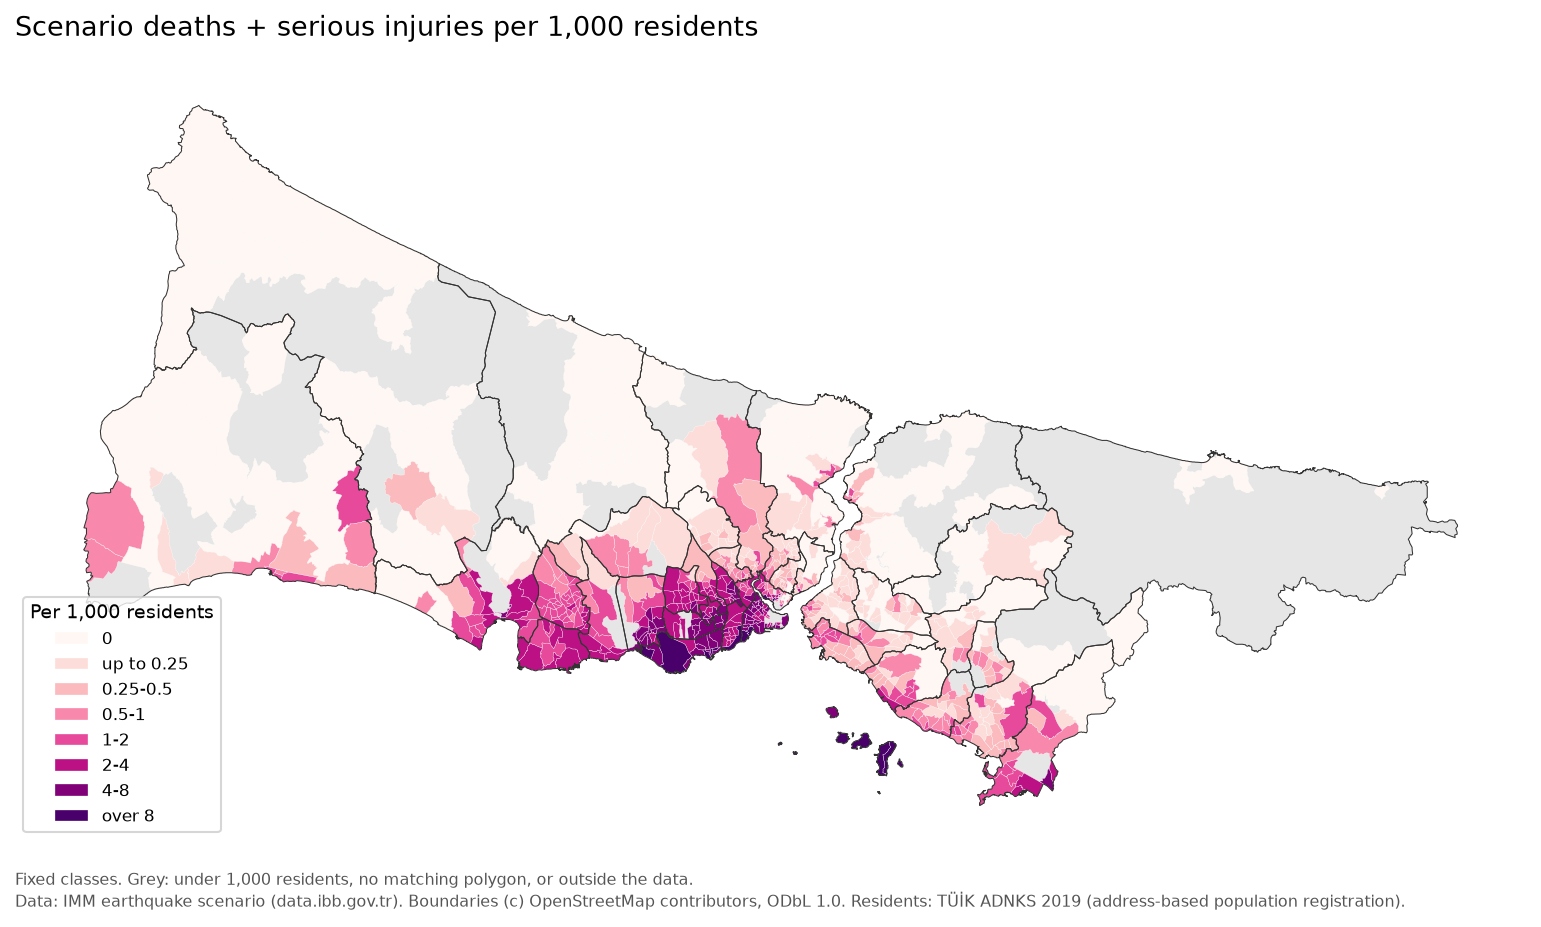

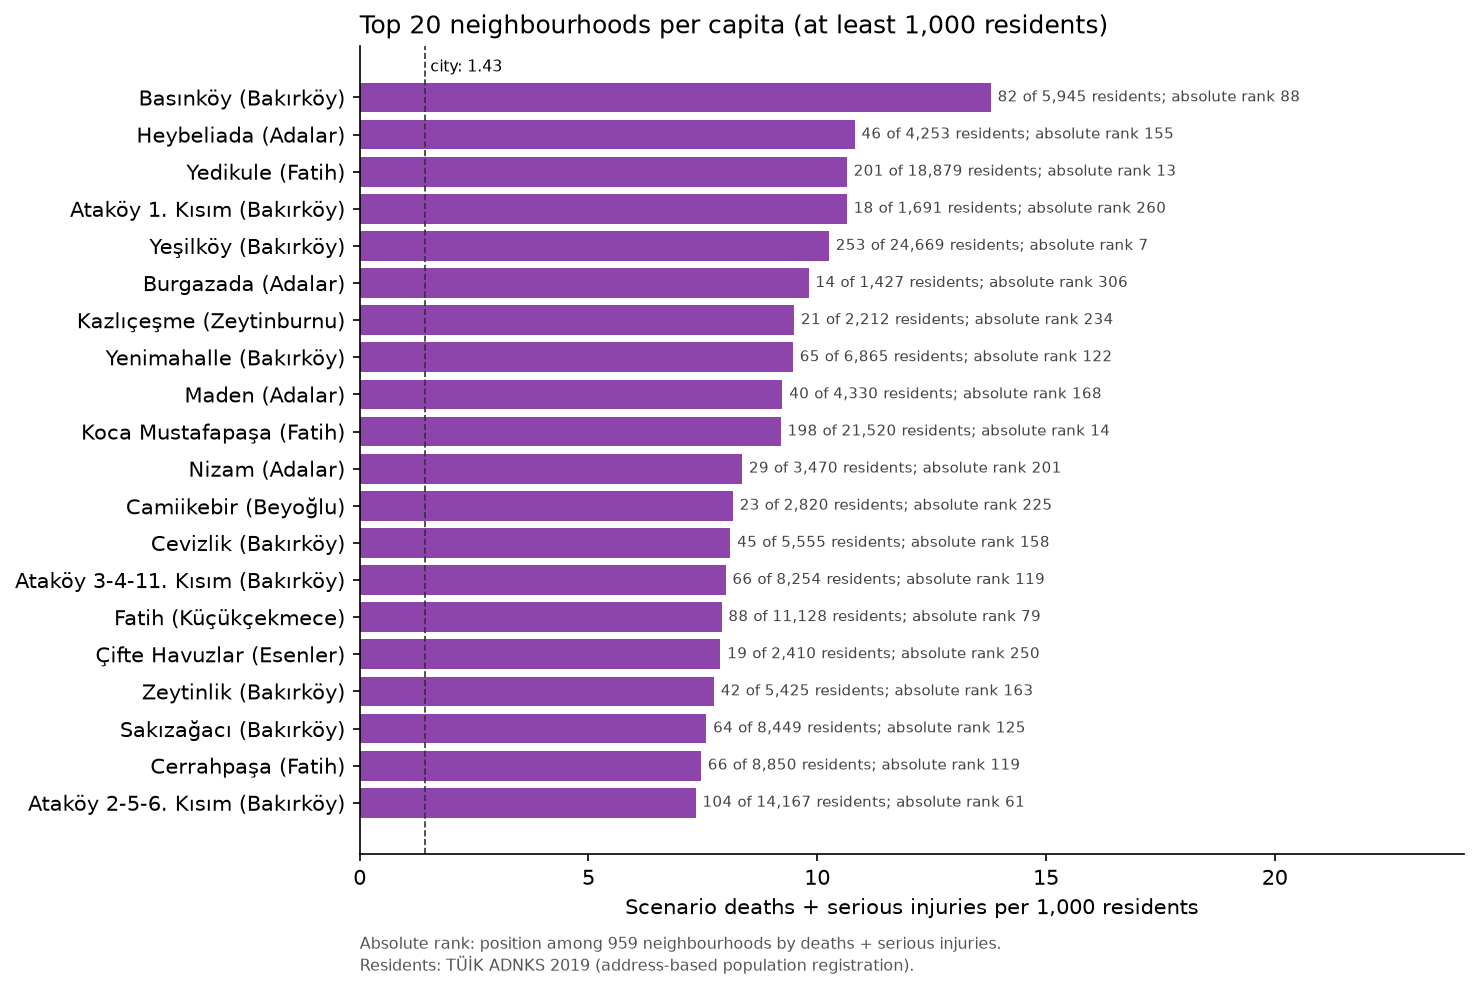

In [18]:
pc_cols = ["district", "neighbourhood", "mahalle_koy_uavt", "population", "buildings", "eligible",
           "rank_casualties_per_1000", "casualties_per_1000", "deaths_per_1000",
           "rank_damage_index_per_1000", "damage_index_per_1000", "shelter_households_per_1000",
           "shelter_share_est", "damaged_share", "heavy_or_worse_share",
           "damage_index_per_100_buildings", "residents_per_building", "share_pre_1980",
           "deaths_serious", "can_kaybi_sayisi", "damage_index", "rank", "gecici_barinma"]
nb.sort_values(["rank_casualties_per_1000", "casualties_per_1000"], ascending=[True, False])[
    pc_cols].round(4).to_csv(RES / "per_capita_neighbourhoods.csv", index=False)
popn.join_report(nb, tuik_without_scenario).to_csv(RES / "population_join_report.csv", index=False)

plots.choropleth(
    nb.assign(casualties_per_1000=nb["casualties_per_1000"].where(nb["eligible"])),
    districts, "casualties_per_1000", "Scenario deaths + serious injuries per 1,000 residents",
    "Per 1,000 residents", FIG / "per_capita_casualties_map.png", cmap="RdPu",
    bins=[0, 0.25, 0.5, 1, 2, 4, 8, 14],
    labels=["0", "up to 0.25", "0.25-0.5", "0.5-1", "1-2", "2-4", "4-8", "over 8"],
    note="Fixed classes. Grey: under 1,000 residents, no matching polygon, or outside the data.",
    source_note=plots.SOURCE_NOTE + " " + plots.POPULATION_NOTE)
plots.choropleth(
    nb.assign(pct=100 * nb["heavy_or_worse_share"]), districts, "pct",
    "Share of buildings with heavy or very heavy damage", "% of buildings",
    FIG / "heavy_damage_share_map.png", cmap="YlOrRd", bins=[0, 1, 2, 4, 6, 10, 15, 25],
    labels=["0", "up to 1", "1-2", "2-4", "4-6", "6-10", "10-15", "over 15"],
    source_note=plots.SOURCE_NOTE
    + " Building stock: IMM 2017 neighbourhood building counts (1 to 19 floors).")
plots.per_capita_bar(nb, FIG / "per_capita_top_neighbourhoods.png")
plots.per_capita_scatter(nb, FIG / "per_capita_vs_absolute.png")
plots.district_per_capita_bar(dist_pc, FIG / "district_per_capita.png")
# per_capita_vs_absolute, district_per_capita and heavy_damage_share_map are saved, not shown.
for name in ["per_capita_casualties_map", "per_capita_top_neighbourhoods"]:
    display(Image(filename=str(FIG / f"{name}.png"), width=850))

**Findings.** Per-capita and absolute casualty rankings agree on the broad pattern (Spearman
0.93 over 811 neighbourhoods, 0.84 when the 204 neighbourhoods with no casualties are left
out), but they pick different places at the top: only Yeşilköy is in both top-10 lists, and the
top-50 lists share 14 neighbourhoods. Six of the absolute top 10 are large neighbourhoods in
Bahçelievler with 61,700 to 86,000 residents and 3.1 to 5.5 casualties per 1,000. The per-capita
top 10 is made of Bakırköy, Adalar, Fatih and Zeytinburnu neighbourhoods with 9 to 14 per 1,000,
several of them small (Ataköy 1. Kısım, 1,691 residents, absolute rank 260). At district level
Adalar has the highest rate (9.0 per 1,000) but ranks 22nd by count; Bakırköy (5th by count)
and Fatih (2nd by count) come second and third.

The damage index per resident is a weaker guide to casualties per resident than the counts
suggest: Adalar has the five highest values because it has many old buildings and few
registered residents (the islands have a large seasonal population that ADNKS does not count).

### Residents as model exposure

A Poisson GLM with `log(residents)` as a fixed offset models casualties per resident; a second
variant uses `log(residents)` as an ordinary feature. Both use the same folds as section 4. The
offset is implemented by fitting the rate `y / residents` with sample weights equal to the
residents, which gives the same estimating equations as an offset term.

In [19]:
exp_folds, exp_summary, _ = modeling.exposure_cv(nb)
exp_folds.round(4).to_csv(RES / "exposure_cv_folds.csv", index=False)
exp_summary.round(3).to_csv(RES / "exposure_cv_summary.csv", index=False)
exp_summary.round(3)

,split,model,r2_mean,r2_std,mae_mean,mae_std,poisson_dev_mean,poisson_dev_std
0,random 5-fold,Poisson GLM (damage only),0.763,0.060,10.219,1.705,9.416,1.597
1,random 5-fold,Poisson GLM + log(residents) as feature,0.880,0.052,6.629,1.258,3.724,0.433
2,random 5-fold,Poisson GLM + log(residents) offset,0.873,0.043,8.075,0.768,5.538,0.496
3,grouped by district 5-fold,Poisson GLM (damage only),0.652,0.253,10.682,3.530,10.055,3.884
4,grouped by district 5-fold,Poisson GLM + log(residents) as feature,0.840,0.099,7.051,2.440,4.126,0.488
5,grouped by district 5-fold,Poisson GLM + log(residents) offset,0.864,0.051,8.097,2.516,5.672,1.062


Adding residents improves every metric in both split schemes. With district-held-out folds,
mean R² rises from 0.652 to 0.864 with the offset (fold standard deviation falls from 0.253 to
0.051) and to 0.840 with residents as a feature; mean Poisson deviance falls from 10.06 to 5.67
and 4.13. This is expected rather than a discovery: the loss estimation project distributes the
registered night-time population over buildings before it computes casualties, so residents are
an input of the scenario model. It shows that the published casualties are much easier to
reproduce once exposure is known, and that the remaining district-to-district differences in
section 4 are partly differences in how many people live in the damaged buildings.

## 6. Infrastructure and shelter

Six columns were loaded but not analysed so far. The IMM data dictionary describes them only as
counts. The project report (Boğaziçi University KOERI for IMM, "İstanbul İli Olası Deprem Kayıp
Tahminlerinin Güncellenmesi Projesi", 2019) and the IMM district booklets give the units:

| Column | Meaning | City total |
| --- | --- | --- |
| `dogalgaz_boru_hasari` | natural gas pipes: estimated repair points | 356 |
| `icme_suyu_boru_hasari` | drinking water pipes: estimated repair points | 461 |
| `atik_su_boru_hasari` | wastewater pipes: estimated repair points | 1,042 |
| `gecici_barinma` | temporary shelter need, households | 835,918 |
| `hastanede_tedavi_sayisi` | injured needing hospital treatment | 39,636 |
| `hafif_yarali_sayisi` | lightly injured | 75,240 |

The report states that the pipe figures are sums of repair needs computed per grid cell, not
counts of individual leaks or breaks, and that shelter need counts the households living in
residential buildings with moderate, heavy or very heavy damage. Its headline shelter figure is
about 640,000 households; the neighbourhood table sums to 835,918, and the source does not
explain the difference.

In [20]:
nb = infrastructure.add_utility_index(nb)
desc = infrastructure.describe_columns(nb)
desc.round(3).to_csv(RES / "infrastructure_columns.csv", index=False)
counts = infrastructure.value_counts_table(nb)
counts.to_csv(RES / "infrastructure_value_counts.csv", index=False)
display(desc.round(3))
counts

,column,meaning,all_integer,zero_share,mean,median,p90,max,city_total,top10pct_share_of_total
0,dogalgaz_boru_hasari,natural gas pipe repair points,True,0.679,0.371,0.0,1.0,4,356,0.404
1,icme_suyu_boru_hasari,drinking water pipe repair points,True,0.616,0.481,0.0,1.0,7,461,0.410
2,atik_su_boru_hasari,wastewater pipe repair points,True,0.396,1.087,1.0,2.0,14,1042,0.425
3,gecici_barinma,temporary shelter need (households),True,0.003,871.656,412.0,2384.0,9075,835918,0.430
4,hastanede_tedavi_sayisi,injured needing hospital treatment,True,0.225,41.331,11.0,128.2,592,39636,0.554
5,hafif_yarali_sayisi,lightly injured,True,0.166,78.457,26.0,238.0,1028,75240,0.524


,repair_points,natural gas,drinking water,wastewater
0,0,651,591,380
1,1,272,308,367
2,2,27,42,117
3,3,6,10,39
4,4,3,3,23
5,5,0,4,9
6,7,0,1,6
7,6,0,0,10
8,8,0,0,2
9,9,0,0,2


All six columns are non-negative integers. Pipe repair points are sparse: 68 percent of
neighbourhoods have no gas repair point, 62 percent no drinking water point and 40 percent no
wastewater point, and the maximum is 4, 7 and 14.

**Combined index.** Each utility count is divided by its city-wide mean per neighbourhood and
the three ratios are averaged, so 1 means the repair need of an average neighbourhood and zero
stays zero. Z-scores were not used because two thirds of the gas values are zero and would get
the same negative score; equal weights are used because the table says nothing about the
relative consequences of a gas, water or wastewater repair. A rank-based alternative (mean
percentile rank) orders neighbourhoods almost identically (Spearman 0.999).

In [21]:
dist_inf = infrastructure.district_totals(nb)
dist_inf.round(3).to_csv(RES / "infrastructure_districts.csv", index=False)
top_inf = infrastructure.top_neighbourhoods(nb)
top_inf.round(3).to_csv(RES / "infrastructure_top_neighbourhoods.csv", index=False)
print("index vs rank-based alternative, Spearman:",
      round(spearmanr(nb["utility_index"], nb["utility_rank_score"]).statistic, 4))
display(dist_inf.head(10).round(2))
top_inf[top_inf["measure"] == "combined index"].round(2)

index vs rank-based alternative, Spearman: 0.9995


,district,dogalgaz_boru_hasari,icme_suyu_boru_hasari,atik_su_boru_hasari,gecici_barinma,hastanede_tedavi_sayisi,hafif_yarali_sayisi,damaged_buildings,damage_index,population,neighbourhoods,utility_points_total,shelter_households_per_damaged_building,shelter_households_per_1000
0,Beylikdüzü,21,32,72,26670,1456,2655,8606,1183.02,352398,10,125,3.10,75.68
1,Esenyurt,24,28,63,67410,2789,5441,24914,2531.54,954579,43,115,2.71,70.62
2,Büyükçekmece,26,33,54,24298,885,1754,18063,2106.04,254103,24,113,1.35,95.62
3,Küçükçekmece,21,25,63,72774,4079,7413,26633,3721.78,792820,21,109,2.73,91.79
4,Avcılar,19,22,54,34941,1385,2799,16324,1603.70,448882,10,95,2.14,77.84
5,Bahçelievler,17,21,52,61199,4261,7599,17640,2301.52,611059,11,90,3.47,100.15
6,Bağcılar,16,20,52,59513,3148,5869,26019,2816.54,745125,22,88,2.29,79.87
7,Silivri,21,29,36,13481,246,566,21303,2252.94,193680,35,86,0.63,69.60
8,Tuzla,14,19,48,21417,808,1565,15365,1826.78,267396,17,81,1.39,80.09
9,Bakırköy,15,17,48,28910,2701,4610,9421,1853.18,229239,15,80,3.07,126.11


,measure,position,district,neighbourhood,value,damage_index
30,combined index,1,Beylikdüzü,Dereağzı,12.74,239.28
31,combined index,2,Beylikdüzü,Yakuplu,11.05,280.40
32,combined index,3,Beylikdüzü,Kavaklı,10.15,145.88
33,combined index,4,Bakırköy,Yeşilköy,8.84,438.02
34,combined index,5,Avcılar,Cihangir,8.23,213.72
35,combined index,6,Avcılar,Yeşilkent,7.90,398.04
36,combined index,7,Beylikdüzü,Adnan Kahveci,7.72,110.18
37,combined index,8,Silivri,Selimpaşa,7.69,221.28
38,combined index,9,Bakırköy,Şenlikköy,7.23,296.06
39,combined index,10,Beylikdüzü,Marmara,6.92,95.96


In [22]:
corr = infrastructure.correlations(nb)
corr.round(3).to_csv(RES / "infrastructure_correlations.csv", index=False)
ratio = pd.Series(infrastructure.shelter_ratio_fit(nb)).round(3).rename("value")
ratio.to_csv(RES / "shelter_ratio.csv", index_label="statistic")
display(corr.round(3))
ratio

,x,y,n,spearman,pearson_log1p
0,damage_index,dogalgaz_boru_hasari,959,0.612,0.597
1,damage_index,icme_suyu_boru_hasari,959,0.669,0.645
2,damage_index,atik_su_boru_hasari,959,0.810,0.779
3,damage_index,utility_index,959,0.799,0.734
4,damaged_buildings,dogalgaz_boru_hasari,959,0.631,0.578
5,damaged_buildings,icme_suyu_boru_hasari,959,0.675,0.616
6,damaged_buildings,atik_su_boru_hasari,959,0.810,0.747
7,damaged_buildings,gecici_barinma,959,0.876,0.858
8,moderate_or_worse,gecici_barinma,959,0.854,0.832
9,damage_index,gecici_barinma,959,0.849,0.827


city_households_per_moderate_or_worse_building    4.301
neighbourhood_ratio_median                        3.508
neighbourhood_ratio_p10                           0.871
neighbourhood_ratio_p90                           7.501
Name: value, dtype: float64

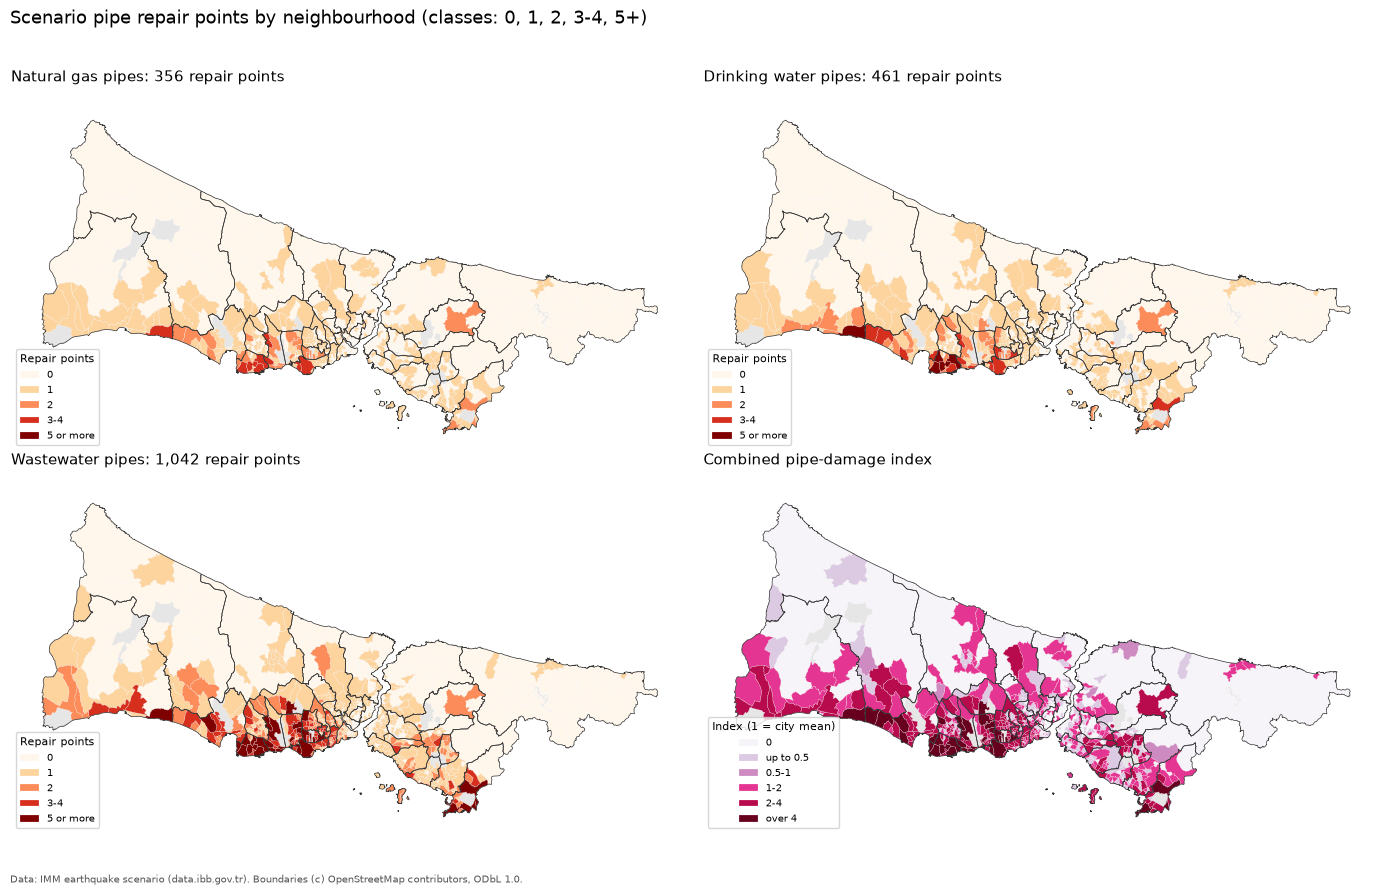

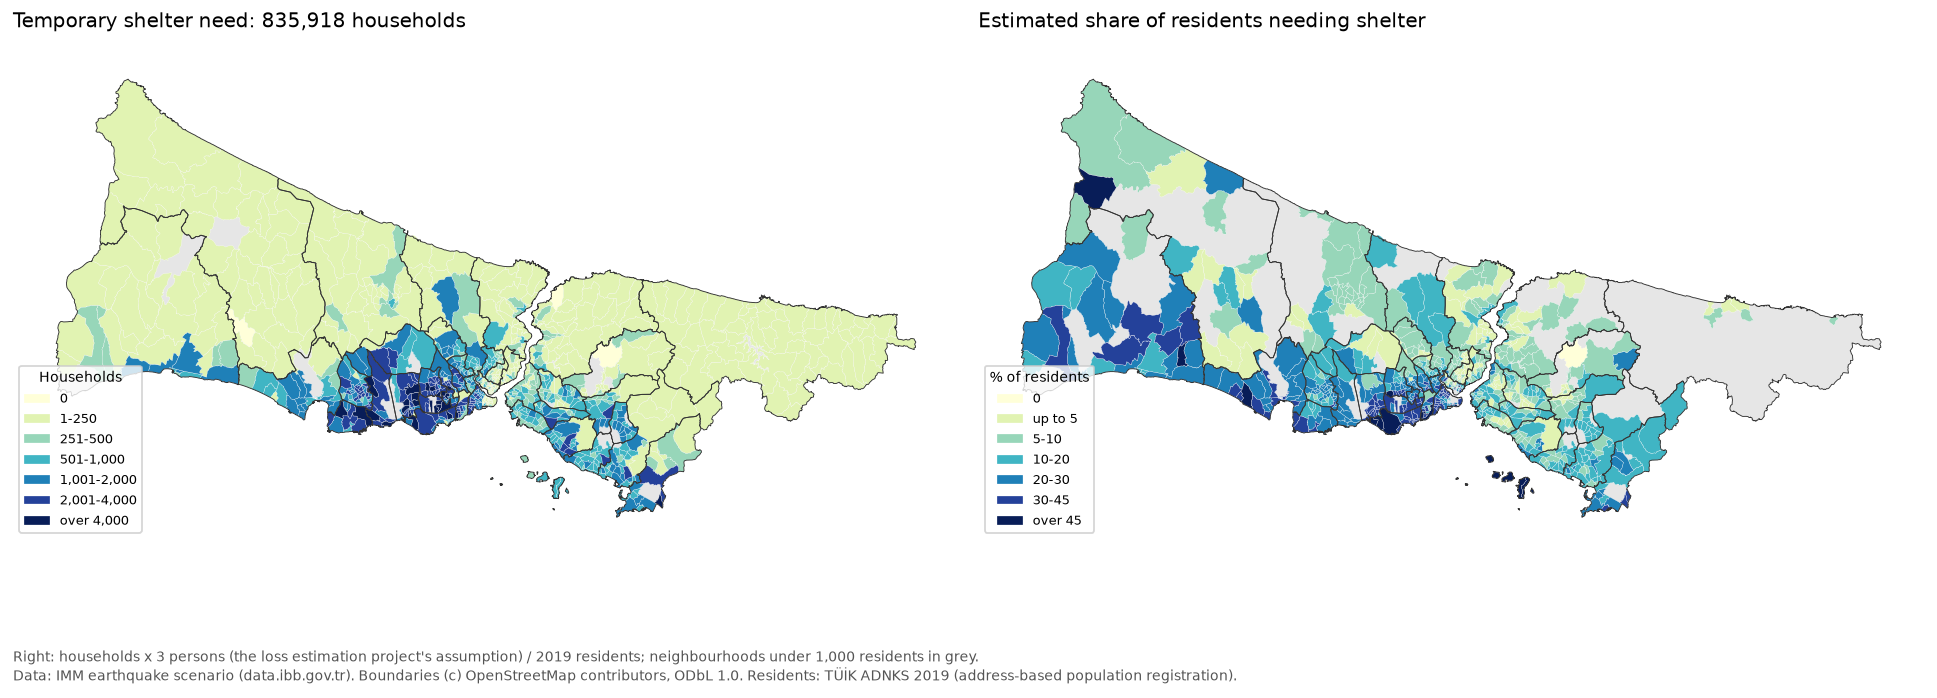

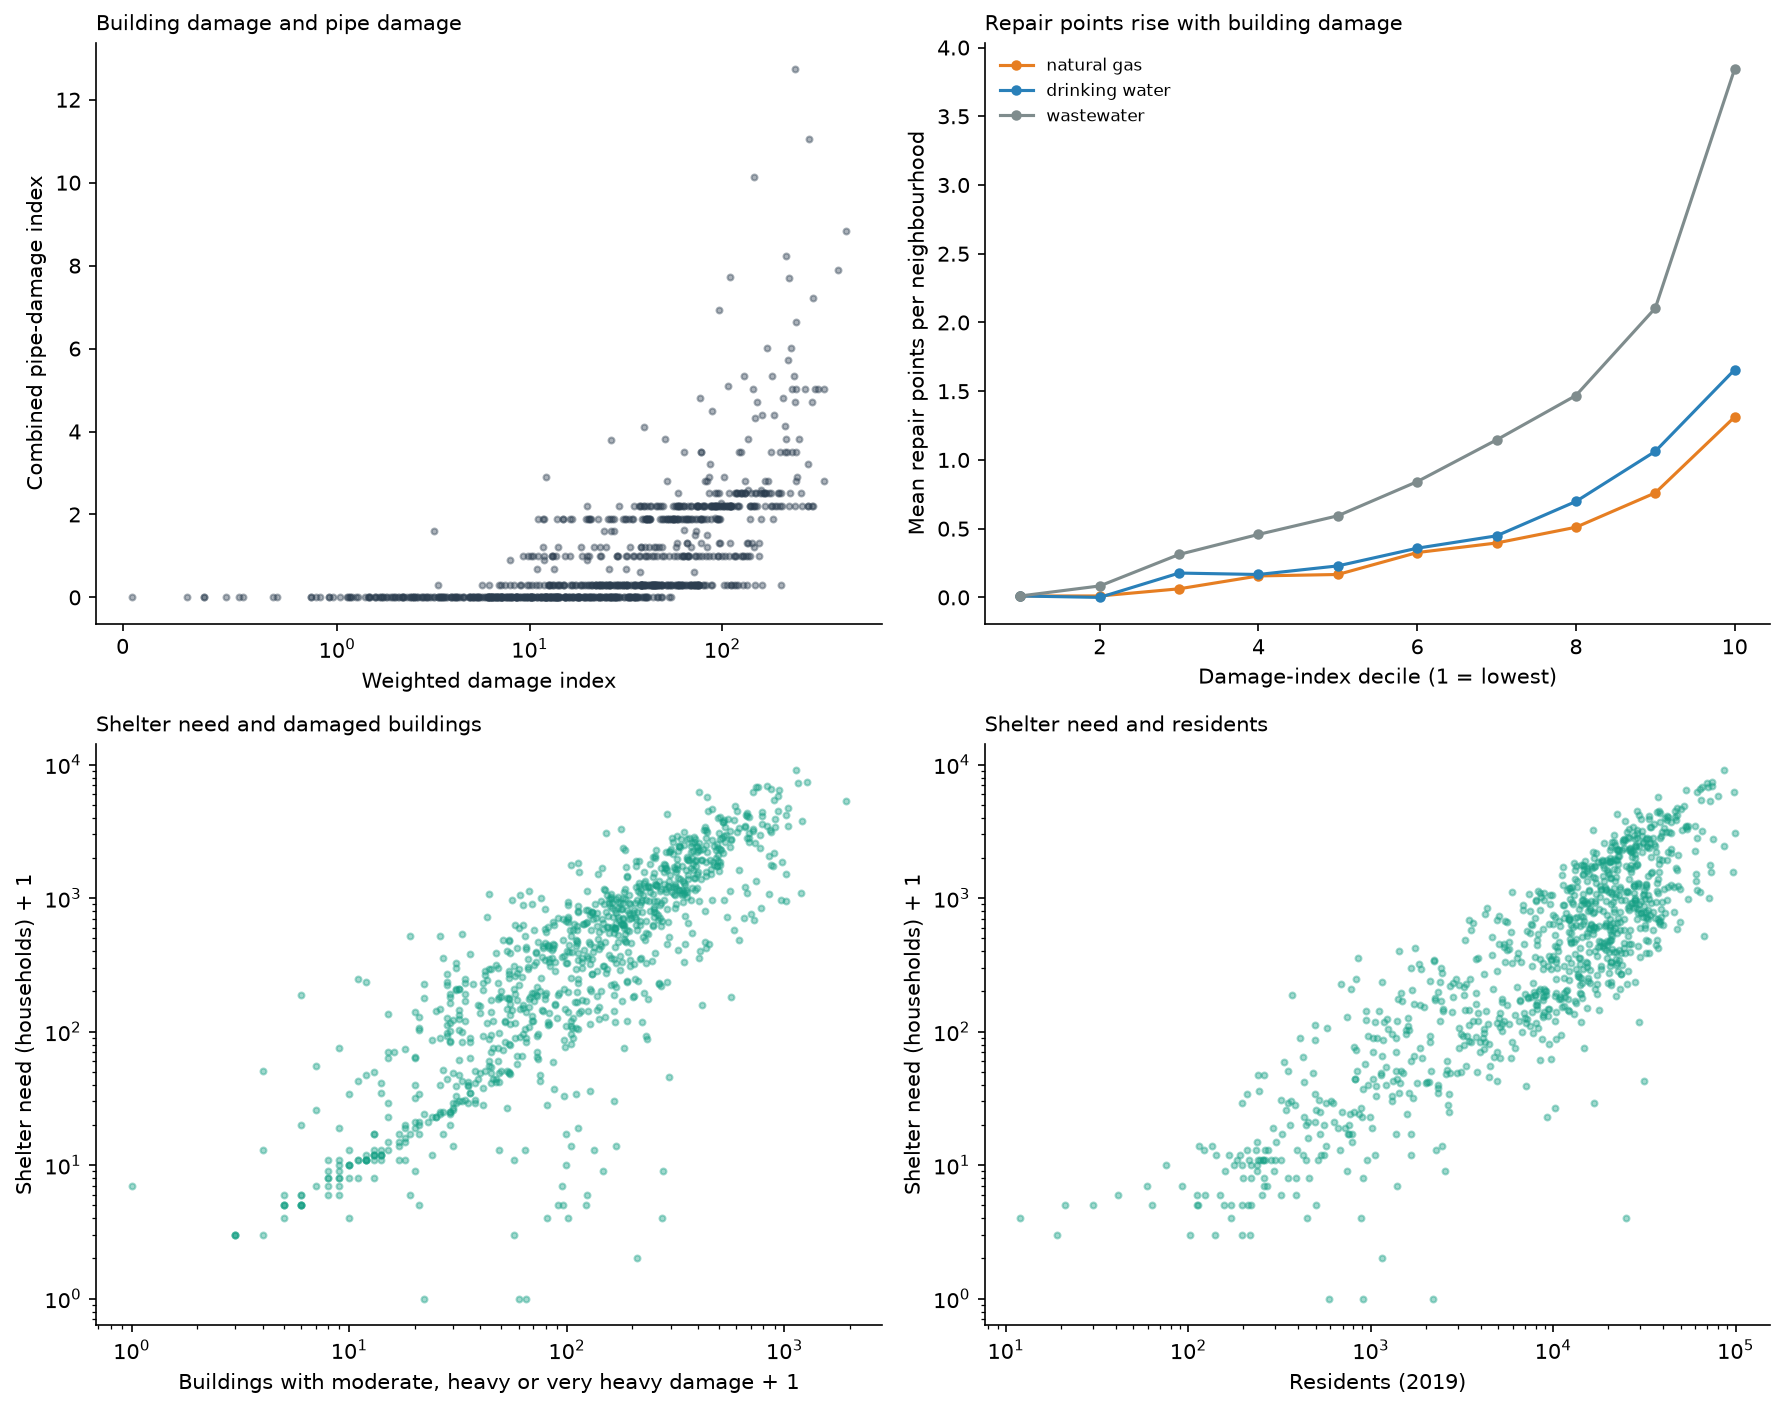

In [23]:
plots.pipeline_maps(nb, districts, FIG / "pipeline_damage_maps.png")
plots.shelter_maps(nb, districts, FIG / "shelter_need_maps.png")
plots.infrastructure_scatter(nb, FIG / "infrastructure_relationships.png")
for name in ["pipeline_damage_maps", "shelter_need_maps", "infrastructure_relationships"]:
    display(Image(filename=str(FIG / f"{name}.png"), width=850))

**Findings.**

- Pipe repair points follow building damage: Spearman 0.81 between the damage index and
  wastewater repair points, 0.67 for drinking water and 0.61 for gas (0.80 for the combined
  index). Mean repair points per neighbourhood rise across damage-index deciles, most steeply in
  the top two. Both
  quantities come from the same ground-motion field, so this is shared hazard, not one damage
  causing the other. Pipe length per neighbourhood is not in the table, so repair points cannot
  be turned into a rate per kilometre.
- The west and south-west coast leads on pipe damage. Beylikdüzü has the most repair points of
  any district (125 over the three networks) although it ranks 11th by casualties;
  Esenyurt, Büyükçekmece and Küçükçekmece follow. The top neighbourhoods on the combined index
  are Dereağzı, Yakuplu and Kavaklı (Beylikdüzü) and Yeşilköy (Bakırköy).
- Shelter need tracks damaged buildings (Spearman 0.88) and residents (0.85). City-wide there are
  4.3 shelter households per building with moderate or worse damage. Using the project's own
  assumption of 3 persons per household, 835,918 households correspond to about 16 percent of
  2019 residents; at district level it is 61 percent in Adalar, 38 percent in Bakırköy and
  32 percent in Fatih. The estimate divides household counts derived from the building
  inventory by registered residents from another source, so the 12 neighbourhoods above 50
  percent should be read with caution.

## 7. Interactive map

Saved to `maps/istanbul_damage_map.html` (not displayed inline to keep the notebook small). It has one
switchable layer each for the damage index, deaths + serious injuries, deaths + serious injuries per
1,000 residents, the combined pipe-damage index and temporary shelter need.

In [24]:
path = plots.interactive_map(nb, districts, ROOT / "maps" / "istanbul_damage_map.html")
print(path.relative_to(ROOT).as_posix(), f"{path.stat().st_size / 1e6:.1f} MB")

maps/istanbul_damage_map.html 7.3 MB
